#### Step 1:
-Data loading

In [1]:
# import all libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
#load the dataset
df=pd.read_csv('StudentsPerformance.csv')

In [4]:
#display the first 5 rows of the dataset
df.head(5)

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [5]:
#display the last 5 rows of the dataset
df.tail(5)

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77
999,female,group D,some college,free/reduced,none,77,86,86


In [6]:
#cheking the shape of the dataset
df.shape

(1000, 8)

In [7]:
#cheking the name of the columns in the dataset
df.columns

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='object')

### Step 2:
- Data cleaning

In [ ]:
# identify the missing values in the dataset
df.isnull().sum()

In [ ]:
# cheking the duplicate rows in the dataset
df.duplicated()

In [10]:
# cheking the number of duplicate rows in the dataset
df.duplicated().sum()

np.int64(0)

In [11]:
# cleaning column names 
df.columns = df.columns.str.lower().str.replace(' ', '_').str.replace('/', '_')

In [ ]:
# verifying the datatype of each column in the dataset
df.dtypes

### Step 3:
-Data Analysis

In [ ]:
# generating summary statistics of the dataset
df.describe()

In [19]:
 #Analyze numerical columns
print("\n--- 2. Numerical Columns Analysis ---")
num_cols = ['math_score', 'reading_score', 'writing_score']

for col in num_cols:
    avg_val = df[col].mean()
    min_val = df[col].min()
    max_val = df[col].max()
    score_range = max_val - min_val
    print(f"{col.upper()} -> Avg: {avg_val:.2f} | Min: {min_val} | Max: {max_val} | Range: {score_range}")


--- 2. Numerical Columns Analysis ---
MATH_SCORE -> Avg: 66.09 | Min: 0 | Max: 100 | Range: 100
READING_SCORE -> Avg: 69.17 | Min: 17 | Max: 100 | Range: 83
WRITING_SCORE -> Avg: 68.05 | Min: 10 | Max: 100 | Range: 90


In [23]:
# Analyze categorical columns (Counts & Distribution)
print("\n--- 3. Categorical Columns Analysis ---")
cat_cols = ['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course']
for col in cat_cols:
   counts = df[col].value_counts()
print(f"\nValue counts for {col}:")
print(df[col].value_counts())


--- 3. Categorical Columns Analysis ---

Value counts for test_preparation_course:
test_preparation_course
none         642
completed    358
Name: count, dtype: int64


In [ ]:
# Find patterns and trends (e.g. Test Prep vs Scores, Gender vs Scores, etc.)
print("\n--- 4. Patterns & Trends ---")
print("Average scores based on Test Preparation Course:")
print(df.groupby('test_preparation_course')[num_cols].mean())

print("\nAverage scores based on Gender:")
print(df.groupby('gender')[num_cols].mean())

#### ==========================================
### STEP 4: DATA EXPLORATION
#### ==========================================

In [ ]:
# 1. Grouping & Aggregation (Parental Education ke hisab se scores)
print("--- 1. Average Scores by Parental Education Level ---")
print(df.groupby('parental_level_of_education')[['math_score', 'reading_score', 'writing_score']].mean().round(2))

# 2. Filtering Conditions (Students scoring above 80 in ALL three subjects)
high_achievers = df[(df['math_score'] > 80) & (df['reading_score'] > 80) & (df['writing_score'] > 80)]
print(f"\n--- 2. High Achievers (>80 in all subjects): {len(high_achievers)} Students ---")
print(high_achievers[['gender', 'parental_level_of_education', 'math_score', 'reading_score', 'writing_score']].head())

# 3. Sorting (Data ko Total Score ke hisab se Top to Bottom sort karna)
df['total_score'] = df['math_score'] + df['reading_score'] + df['writing_score']
sorted_df = df.sort_values(by='total_score', ascending=False)

print("\n--- 3. Top 5 Students Overall (Sorted by Total Score) ---")
print(sorted_df[['gender', 'test_preparation_course', 'total_score']].head())

##### ==========================================
#### STEP 5: BASIC VISUALIZATION
#### ==========================================

In [ ]:
# set the style of seaborn
sns.set(style="whitegrid")
plt.figure(figsize=(12, 6))

Text(0, 0.5, 'Count')

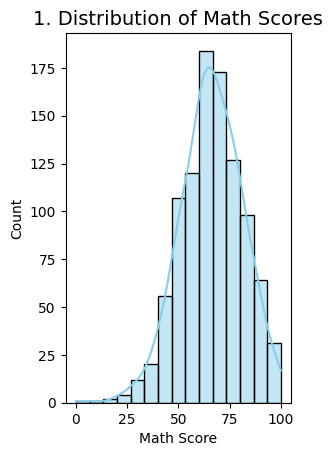

In [26]:
# Plot 1: Histogram of Math Scores
plt.subplot(1, 2, 1)
sns.histplot(df['math_score'], kde=True, color='skyblue', bins=15)
plt.title('1. Distribution of Math Scores', fontsize=14)
plt.xlabel('Math Score')
plt.ylabel('Count')

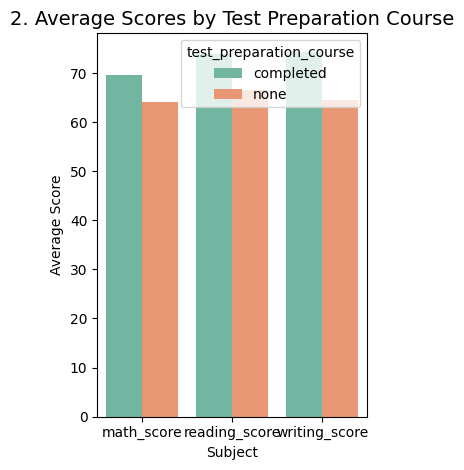

In [27]:
# Plt 2:Bar chat everage score by test preparation course
plt.subplot(1, 2, 2)
prep_scores = df.groupby('test_preparation_course')[['math_score', 'reading_score', 'writing_score']].mean().reset_index()
prep_melted = prep_scores.melt(id_vars='test_preparation_course', var_name='Subject', value_name='Average Score')

sns.barplot(data=prep_melted, x='Subject', y='Average Score', hue='test_preparation_course', palette='Set2')
plt.title('2. Average Scores by Test Preparation Course', fontsize=14)
plt.xlabel('Subject')
plt.ylabel('Average Score')

plt.tight_layout()
plt.show()

- What was cleaned:  Standardized column names by converting to lowercase and replacing spaces/slashes with underscores.   Verified that there were no missing values or duplicate rows in the dataset.   Insights Found:  Test Prep Impact: Students who completed the test preparation course performed significantly better across all subjects, averaging around 70+ compared to ~64-66 for non-completers.   Gender Trends:   Male students scored slightly higher on average in Math (68.7 vs 63.6), whereas Female students scored higher in Reading (72.6 vs 65.5) and Writing (72.5 vs 63.3).   